# 实验 8　主题词典与主题趋势分析

## 任务要求

1. 至少构建 3 个主题词典，例如“战争”“谋略”“忠义”，也可扩展“联盟 / 外交”。
2. 按章节统计每个主题的出现次数或占比，并保存为表格。
3. 绘制主题趋势图，指出哪些章节最能代表某一主题。
4. 比较不同主题的变化特点，反思词典法的优势与局限。

## 主题词典

- 词典文件：`data/lexicons/topic_lexicon.json`（战争、谋略、忠义、联盟 四个主题）。
- 一个词允许同时计入多个主题（重叠计数）；因跨主题的多义词占比较小，重叠计数对整体趋势影响有限。

In [1]:
# 让 notebook 在 notebooks/ 或仓库根目录下都能找到 src/ 包
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "sanguo_nlp").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from sanguo_nlp.paths import FIGURES_DIR, TABLES_DIR, ensure_output_dirs

ensure_output_dirs()
print("已定位仓库根目录:", ROOT.name)

已定位仓库根目录: sanguo-nlp-lab


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from sanguo_nlp.corpus import load_chapters
from sanguo_nlp.lexicons import load_topics
from sanguo_nlp.plotting import use_chinese_font
from sanguo_nlp.topics import count_topics

use_chinese_font()

chapters = load_chapters()
topics = load_topics()
print("主题与词条数:", {topic: len(words) for topic, words in topics.items()})

topic_df = count_topics(chapters, topics)
topic_df.to_csv(TABLES_DIR / "topic_trends.csv", index=False, encoding="utf-8-sig")
topic_df.head()

主题与词条数: {'战争': 24, '谋略': 20, '忠义': 18, '联盟': 14}


,章号,总字符数,战争,谋略,忠义,联盟,战争_占比,谋略_占比,忠义_占比,联盟_占比
0,1,4634,166,16,76,36,0.035822,0.003453,0.016401,0.007769
1,2,5751,191,43,68,16,0.033212,0.007477,0.011824,0.002782
2,3,4961,120,36,28,15,0.024189,0.007257,0.005644,0.003024
3,4,4108,65,25,38,8,0.015823,0.006086,0.009250,0.001947
4,5,5597,231,24,70,43,0.041272,0.004288,0.012507,0.007683


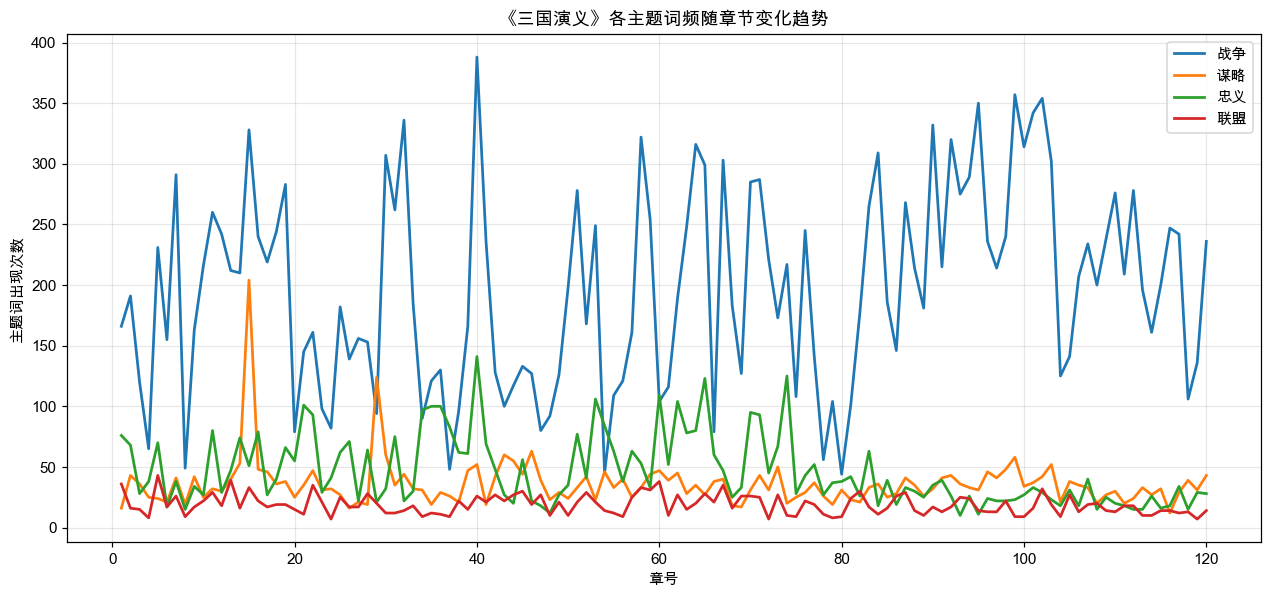

In [3]:
fig, ax = plt.subplots(figsize=(14, 6))
for topic in topics:
    ax.plot(topic_df["章号"], topic_df[topic], label=topic, linewidth=1.8)
ax.set_xlabel("章号")
ax.set_ylabel("主题词出现次数")
ax.set_title("《三国演义》各主题词频随章节变化趋势")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(FIGURES_DIR / "topic_trend.png")
plt.show()

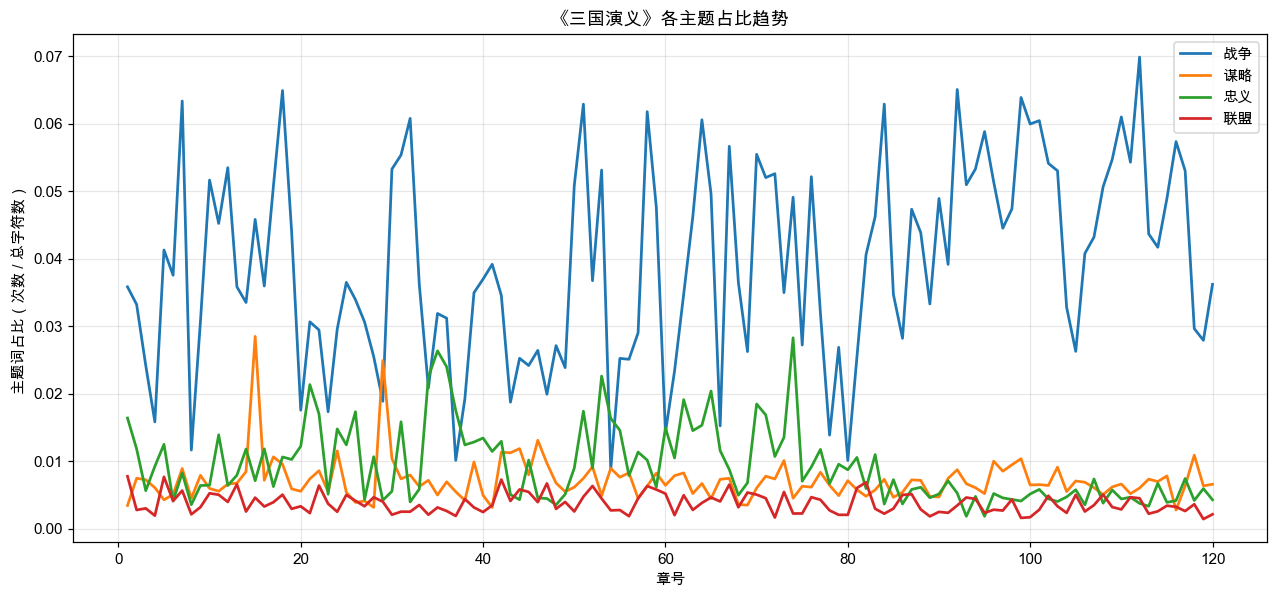

In [4]:
fig, ax = plt.subplots(figsize=(14, 6))
for topic in topics:
    ax.plot(topic_df["章号"], topic_df[f"{topic}_占比"], label=topic, linewidth=1.8)
ax.set_xlabel("章号")
ax.set_ylabel("主题词占比（次数 / 总字符数）")
ax.set_title("《三国演义》各主题占比趋势")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(FIGURES_DIR / "topic_proportion_trend.png")
plt.show()

In [5]:
for topic in topics:
    peak = topic_df.loc[topic_df[topic].idxmax()]
    print(
        f"【{topic}】峰值：第{int(peak['章号'])}回，出现 {int(peak[topic])} 次；"
        f"均值 {topic_df[topic].mean():.1f}，标准差 {topic_df[topic].std():.1f}"
    )

【战争】峰值：第40回，出现 388 次；均值 196.8，标准差 82.7
【谋略】峰值：第15回，出现 204 次；均值 36.0，标准差 20.5
【忠义】峰值：第40回，出现 141 次；均值 46.2，标准差 28.8
【联盟】峰值：第5回，出现 43 次；均值 18.8，标准差 8.0


## 结果解释与反思

- **战争**主题在全书中始终占主导，且在第 5、30、40—50、90—105 回等战争密集段达到峰值，与官渡、赤壁、北伐等关键战役吻合。
- **谋略**主题波动较大，常在战役前后出现尖峰；**忠义**主题整体平稳，但在关羽、诸葛亮相关章节会抬升；**联盟**主题词条较少，趋势最平缓。
- **词典法的优势**：无需训练数据，计算高效，可解释性强，每个得分都能追溯到具体词条，便于按领域知识增删词条。
- **词典法的局限**：词表覆盖不全（如漏掉“鏖战”“讨伐”会低估战争强度）；多义词带来噪声（“计”也可能出现在“计较”中）；难以处理同义词变体与否定语境（“不忠”仍会命中“忠”）。

**实验记录**

- 本实验未出现报错；AI 助手协助整理初始主题词表，人工补充了《三国演义》中常见的同义表达。